In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.sparse.linalg import svds

In [2]:
movies = pd.read_csv('/content/movies.csv')
ratings = pd.read_csv('/content/ratings.csv')

print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)

Movies shape: (10329, 3)
Ratings shape: (105339, 4)


In [3]:
# Drop unnecessary columns if exist
ratings = ratings[['userId', 'movieId', 'rating']]

In [4]:
user_item_matrix = ratings.pivot(index='userId', columns='movieId', values='rating').fillna(0)

print("User-Item Matrix Shape:", user_item_matrix.shape)

User-Item Matrix Shape: (668, 10325)


In [5]:
user_ratings_mean = np.mean(user_item_matrix, axis=1)
matrix_demeaned = user_item_matrix - user_ratings_mean.values.reshape(-1, 1)

In [7]:
k = 50  # latent factors
U, sigma, Vt = svds(matrix_demeaned.values, k=k)

sigma = np.diag(sigma)

In [8]:
predicted_ratings = np.dot(np.dot(U, sigma), Vt) + user_ratings_mean.values.reshape(-1, 1)

pred_df = pd.DataFrame(predicted_ratings, columns=user_item_matrix.columns, index=user_item_matrix.index)

In [9]:
actual = user_item_matrix.values.flatten()
predicted = pred_df.values.flatten()

rmse = np.sqrt(mean_squared_error(actual, predicted))
mae = mean_absolute_error(actual, predicted)

print(f"RMSE: {rmse}")
print(f"MAE: {mae}")


RMSE: 0.29214472495282656
MAE: 0.08217636541385222


In [10]:
def recommend_movies(user_id, num_recommendations=10):
    user_row = pred_df.loc[user_id]
    already_rated = user_item_matrix.loc[user_id]

    recommendations = user_row[already_rated == 0].sort_values(ascending=False)
    top_movies = recommendations.head(num_recommendations)

    return movies[movies['movieId'].isin(top_movies.index)]

# Example
print("\nTop Recommendations for User 1:")
print(recommend_movies(1))


Top Recommendations for User 1:
      movieId                                              title  \
0           1                                   Toy Story (1995)   
258       293  Léon: The Professional (a.k.a. The Professiona...   
484       541                                Blade Runner (1982)   
956      1193             One Flew Over the Cuckoo's Nest (1975)   
1050     1291          Indiana Jones and the Last Crusade (1989)   
1843     2329                          American History X (1998)   
3149     3996  Crouching Tiger, Hidden Dragon (Wo hu cang lon...   
3322     4226                                     Memento (2000)   
4802     6539  Pirates of the Caribbean: The Curse of the Bla...   
7669    58559                            Dark Knight, The (2008)   

                                           genres  
0     Adventure|Animation|Children|Comedy|Fantasy  
258                   Action|Crime|Drama|Thriller  
484                        Action|Sci-Fi|Thriller  
956       

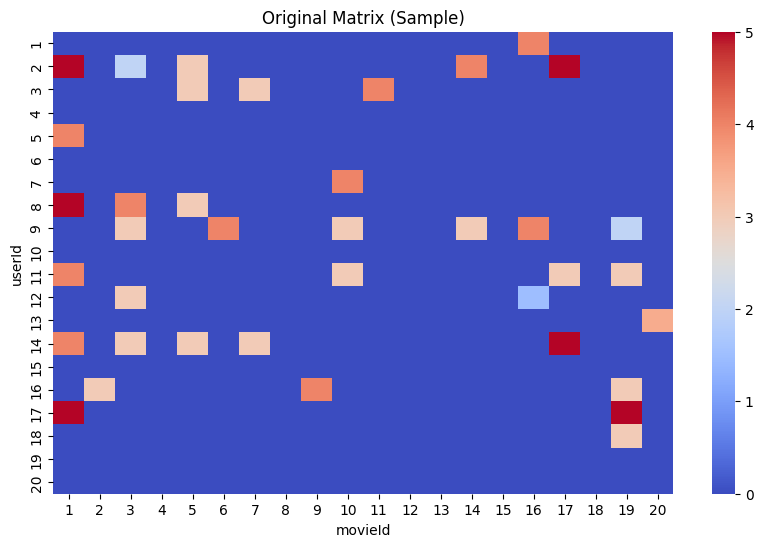

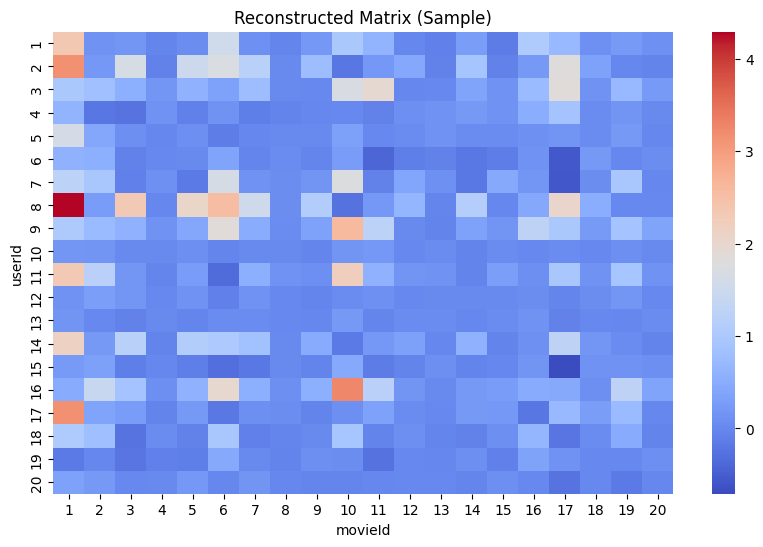

In [11]:
# 1. Heatmap (sample users)
plt.figure(figsize=(10,6))
sns.heatmap(user_item_matrix.iloc[:20, :20], cmap='coolwarm')
plt.title("Original Matrix (Sample)")
plt.show()

plt.figure(figsize=(10,6))
sns.heatmap(pred_df.iloc[:20, :20], cmap='coolwarm')
plt.title("Reconstructed Matrix (Sample)")
plt.show()

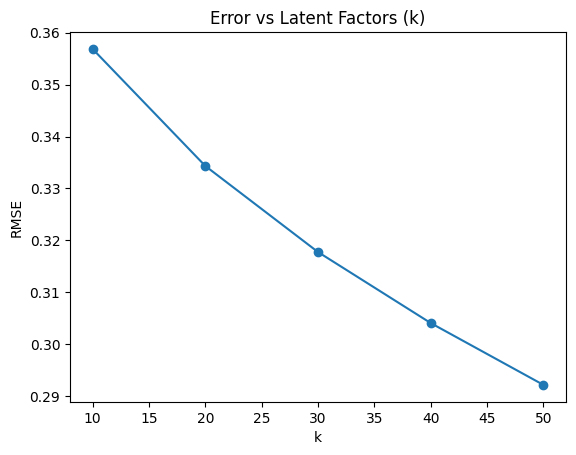

In [14]:
k_values = [10, 20, 30, 40, 50]
rmse_list = []

for k in k_values:
    U, sigma, Vt = svds(matrix_demeaned.values, k=k)
    sigma = np.diag(sigma)

    pred = np.dot(np.dot(U, sigma), Vt) + user_ratings_mean.values.reshape(-1, 1)

    rmse_k = np.sqrt(mean_squared_error(user_item_matrix.values.flatten(), pred.flatten()))
    rmse_list.append(rmse_k)

plt.plot(k_values, rmse_list, marker='o')
plt.title("Error vs Latent Factors (k)")
plt.xlabel("k")
plt.ylabel("RMSE")
plt.show()

In [16]:
print("\nAnalysis:")
print("- Increasing k reduces error initially.")
print("- Too large k may cause overfitting.")
print("- Too small k leads to underfitting.")
print("- SVD captures latent patterns in user behavior.")


Analysis:
- Increasing k reduces error initially.
- Too large k may cause overfitting.
- Too small k leads to underfitting.
- SVD captures latent patterns in user behavior.
